In [18]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pyrfu
from pyrfu import mms
from pyrfu import pyrf
from pyrfu.plot import plot_line, make_labels
import matplotlib
pyrfu.plot.set_color_cycle(pal = "pyrfu")
from mms_codes.resample2 import resample
import pickle
import copy
from IPython.display import display, Latex

mms.db_init(default="local", local="/data/mms")


[13-Mar-26 13:08:57] INFO: Updating MMS data access configuration in /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/config.json...


[13-Mar-26 13:08:57] INFO: Updating MMS SDC credentials in /homelocal/apostolosk/.config/python_keyring...


In [21]:
w_ti = 10
ss = "b"
# with open(f"epoch_analysis_{w_ti}{ss}_84DFs.pickle", 'rb') as file:
    # dict_ts_all = pickle.load(file)

with open("../epoch_analysis_data/epoch_analysis_10b_84DFs_v2.pickle", 'rb') as file:
    dict_ts_all = pickle.load(file)

dict_ts = dict_ts_all
idx_tint_negVi = [15, 18, 21, 33, 52, 75]

for idx in idx_tint_negVi:
    if idx in dict_ts.keys():
        del dict_ts[idx]

dict_ts_new_idx = {}
for it in range(len(dict_ts.keys())):
    
    dict_ts_new_idx[it] = dict_ts[list(dict_ts.keys())[it]]

dict_ts = dict_ts_new_idx

In [22]:
bs = np.array([dict_ts_all[i]['b'] for i in dict_ts_all.keys()])
display(Latex(f"$\langle b \\rangle = ({np.mean(bs):.2f} \pm {np.std(bs):.2f}) ~ \\rm s$"))

[13-Mar-26 13:10:22] WARNING: <>:2: SyntaxWarning: invalid escape sequence '\l'

[13-Mar-26 13:10:22] WARNING: <>:2: SyntaxWarning: invalid escape sequence '\p'

[13-Mar-26 13:10:22] WARNING: <>:2: SyntaxWarning: invalid escape sequence '\l'

[13-Mar-26 13:10:22] WARNING: <>:2: SyntaxWarning: invalid escape sequence '\p'

[13-Mar-26 13:10:22] WARNING: /tmp/ipykernel_421036/3898260147.py:2: SyntaxWarning: invalid escape sequence '\l'
  display(Latex(f"$\langle b \\rangle = ({np.mean(bs):.2f} \pm {np.std(bs):.2f}) ~ \\rm s$"))

[13-Mar-26 13:10:22] WARNING: /tmp/ipykernel_421036/3898260147.py:2: SyntaxWarning: invalid escape sequence '\p'
  display(Latex(f"$\langle b \\rangle = ({np.mean(bs):.2f} \pm {np.std(bs):.2f}) ~ \\rm s$"))



<IPython.core.display.Latex object>

In [23]:
dict_ts_new = copy.deepcopy(dict_ts)

f_ss_b = np.zeros(len(dict_ts_new.keys()))
f_ss_w = np.zeros(len(dict_ts_new.keys()))
f_ss_t = np.zeros(len(dict_ts_new.keys()))
f_ss_feeps = np.zeros(len(dict_ts_new.keys()))
f_ss_vi = np.zeros(len(dict_ts_new.keys()))
f_ss_vi_hpca = np.zeros(len(dict_ts_new.keys()))
ss = "b"

feeps_d_name = f"{dict_ts[0]["energy_ranges_feeps"][0][0]}_{dict_ts[0]["energy_ranges_feeps"][0][1]}"

no_feeps = []
no_hpca = []
for it in range(len(dict_ts_new.keys())):

    f_ss_b[it] = pyrf.calc_fs(dict_ts_new[it][f"b_avg_{ss}"])
    f_ss_w[it] = pyrf.calc_fs(dict_ts_new[it][f"w_betatron_{ss}"])
    f_ss_t[it] = pyrf.calc_fs(dict_ts_new[it][f"t_ratio_{ss}"])
    f_ss_vi[it] = pyrf.calc_fs(dict_ts_new[it][f"V_i_avg_{ss}"])

    if f"feeps_en_omni_{feeps_d_name}_norm_{ss}" in dict_ts_new[it].keys():
        no_feeps.append(False)
        f_ss_feeps[it] = pyrf.calc_fs(dict_ts_new[it][f"feeps_en_omni_{feeps_d_name}_norm_{ss}"])
    else:
        no_feeps.append(True)
        f_ss_feeps[it] = np.nan
        
    if f"V_i_avg_hpca_{ss}" in dict_ts_new[it].keys():
        no_hpca.append(False)
        f_ss_vi_hpca[it] = pyrf.calc_fs(dict_ts_new[it][f"V_i_avg_hpca_{ss}"])
    else:
        no_hpca.append(True)
        f_ss_vi_hpca[it] = np.nan

for it in range(len(dict_ts_new.keys())):
    if dict_ts_new[it][f"b_avg_{ss}"].shape[0] == 0:
        dict_ts_new.pop(it
                    )
        continue
    dict_ts_new[it][f"b_avg_{ss}"] = resample(dict_ts_new[it][f"b_avg_{ss}"], dict_ts_new[np.nanargmin(f_ss_b)][f"b_avg_{ss}"], f_s = np.nanmin(f_ss_b))
    dict_ts_new[it][f"dbz_dt_{ss}"] = resample(dict_ts_new[it][f"dbz_dt_{ss}"], dict_ts_new[np.nanargmin(f_ss_b)][f"dbz_dt_{ss}"], f_s = np.nanmin(f_ss_b))
    dict_ts_new[it][f"w_betatron_{ss}"] = resample(dict_ts_new[it][f"w_betatron_{ss}"], dict_ts_new[np.nanargmin(f_ss_w)][f"w_betatron_{ss}"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"w_fermi_{ss}"] = resample(dict_ts_new[it][f"w_fermi_{ss}"], dict_ts_new[np.nanargmin(f_ss_w)][f"w_fermi_{ss}"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"W_betatron_{ss}"] = resample(dict_ts_new[it][f"W_betatron_{ss}"], dict_ts_new[np.nanargmin(f_ss_w)][f"W_betatron_{ss}"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"W_fermi_{ss}"] = resample(dict_ts_new[it][f"W_fermi_{ss}"], dict_ts_new[np.nanargmin(f_ss_w)][f"W_fermi_{ss}"], f_s = np.nanmin(f_ss_w))
   
    dict_ts_new[it][f"kappa_roll_{ss}"] = resample(dict_ts_new[it][f"kappa_roll_{ss}"], dict_ts_new[np.nanargmin(f_ss_w)][f"kappa_roll_{ss}"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"t_ratio_{ss}"] = resample(dict_ts_new[it][f"t_ratio_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"t_ratio_{ss}"], f_s = np.nanmin(f_ss_t))
    dict_ts_new[it][f"temp_{ss}"] = resample(dict_ts_new[it][f"temp_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"temp_{ss}"], f_s = np.nanmin(f_ss_t))
    
    dict_ts_new[it][f"kappa_extra_energy_{ss}"] = resample(dict_ts_new[it][f"kappa_extra_energy_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"kappa_extra_energy_{ss}"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"V_i_avg_{ss}"] = resample(dict_ts_new[it][f"V_i_avg_{ss}"], dict_ts_new[np.nanargmin(f_ss_vi)][f"V_i_avg_{ss}"], f_s = np.nanmin(f_ss_vi))
    dict_ts_new[it][f"n_i_avg_{ss}"] = resample(dict_ts_new[it][f"n_i_avg_{ss}"], dict_ts_new[np.nanargmin(f_ss_vi)][f"n_i_avg_{ss}"], f_s = np.nanmin(f_ss_vi))
    dict_ts_new[it][f"n_e_avg_{ss}"] = resample(dict_ts_new[it][f"n_e_avg_{ss}"], dict_ts_new[np.nanargmin(f_ss_vi)][f"n_e_avg_{ss}"], f_s = np.nanmin(f_ss_t))
    dict_ts_new[it]["pe_perp_B_mag_b"] = resample(dict_ts_new[it]["pe_perp_B_mag_b"], dict_ts_new[np.nanargmin(f_ss_t)]["pe_perp_B_mag_b"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it]["db_dt_uE_dot_gradB_b"] = resample(dict_ts_new[it]["db_dt_uE_dot_gradB_b"], dict_ts_new[np.nanargmin(f_ss_w)]["db_dt_uE_dot_gradB_b"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it]["pe_para_mnv2_b"] = resample(dict_ts_new[it]["pe_para_mnv2_b"], dict_ts_new[np.nanargmin(f_ss_t)]["pe_para_mnv2_b"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it]["u_E_dot_curv_b"] = resample(dict_ts_new[it]["u_E_dot_curv_b"], dict_ts_new[np.nanargmin(f_ss_w)]["u_E_dot_curv_b"], f_s = np.nanmin(f_ss_w))
    
    dict_ts_new[it][f"curv_b"] = resample(dict_ts_new[it][f"curv_b"], dict_ts_new[np.nanargmin(f_ss_w)][f"curv_b"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"db_dt_5ps_b"] = resample(dict_ts_new[it][f"db_dt_5ps_b"], dict_ts_new[np.nanargmin(f_ss_w)][f"db_dt_5ps_b"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"u_E_avg_b"] = resample(dict_ts_new[it][f"u_E_avg_b"], dict_ts_new[np.nanargmin(f_ss_w)][f"u_E_avg_b"], f_s = np.nanmin(f_ss_w))
    dict_ts_new[it][f"uE_dot_gradB_avg_b"] = resample(dict_ts_new[it][f"uE_dot_gradB_avg_b"], dict_ts_new[np.nanargmin(f_ss_w)][f"uE_dot_gradB_avg_b"], f_s = np.nanmin(f_ss_w))

    for ien, en in enumerate(dict_ts_new[it]["energies_fpi"]):

        dict_ts_new[it][f"f_en_omni_{en}_norm_{ss}"] = resample(dict_ts_new[it][f"f_en_omni_{en}_norm_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"f_en_omni_{en}_norm_{ss}"], f_s = np.nanmin(f_ss_t))
        dict_ts_new[it][f"f_en_perp_para_{en}_{ss}"] = resample(dict_ts_new[it][f"f_en_perp_para_{en}_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"f_en_perp_para_{en}_{ss}"], f_s = np.nanmin(f_ss_t))
        dict_ts_new[it][f"f_en_para0_{en}_{ss}"] = resample(dict_ts_new[it][f"f_en_para0_{en}_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"f_en_para0_{en}_{ss}"], f_s = np.nanmin(f_ss_t))
        dict_ts_new[it][f"f_en_para180_{en}_{ss}"] = resample(dict_ts_new[it][f"f_en_para180_{en}_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"f_en_para180_{en}_{ss}"], f_s = np.nanmin(f_ss_t))
        dict_ts_new[it][f"f_en_perp_{en}_{ss}"] = resample(dict_ts_new[it][f"f_en_perp_{en}_{ss}"], dict_ts_new[np.nanargmin(f_ss_t)][f"f_en_perp_{en}_{ss}"], f_s = np.nanmin(f_ss_t))

    if no_feeps[it]:
        print(f"no feeps for {it}")
        continue

    for ien, energy_range in enumerate(dict_ts_new[it]["energy_ranges_feeps"]):

        dict_ts_new[it][f"feeps_en_omni_{energy_range[0]}_{energy_range[1]}_norm_{ss}"] = resample(dict_ts_new[it][f"feeps_en_omni_{energy_range[0]}_{energy_range[1]}_norm_{ss}"], dict_ts_new[np.nanargmin(f_ss_feeps)][f"feeps_en_omni_{energy_range[0]}_{energy_range[1]}_norm_{ss}"], f_s = np.nanmin(f_ss_feeps))

    if no_hpca[it]:
        print(f"no hpca for {it}")
        continue
    dict_ts_new[it][f"V_i_avg_hpca_{ss}"] = resample(dict_ts_new[it][f"V_i_avg_hpca_{ss}"], dict_ts_new[np.nanargmin(f_ss_vi_hpca)][f"V_i_avg_hpca_{ss}"], f_s = np.nanmin(f_ss_vi_hpca))


pop_key = []
for key in dict_ts_new.keys():
    pop_key.append(key)

for new_ky, key in enumerate(pop_key):
    dict_ts_new[new_ky] = dict_ts_new.pop(key)



[13-Mar-26 13:10:23] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/pyrf/calc_fs.py:44: RuntimeWarning: divide by zero encountered in scalar divide
  f_samp = 1e9 / np.median(dt_ns)

[13-Mar-26 13:10:23] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,

[13-Mar-26 13:10:23] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)

[13-Mar-26 13:10:23] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/scipy/interpolate/_interpolate.py:501: RuntimeWarning: invalid value encountered in subtract
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]

[13-Mar-26 13:10:23] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-pa

no hpca for 2
no hpca for 3
no hpca for 4
no hpca for 5
no hpca for 6


[13-Mar-26 13:10:24] WARNING: /homelocal/apostolosk/mms_pyrfu_projects/1/Stats_Betatron_Fermi_DFs/mms_codes/resample2.py:135: RuntimeWarning: divide by zero encountered in scalar divide
  if len(inp_time) / (inp_time[-1] - inp_time[0]) > 2 * sfy:



no feeps for 23


In [24]:
import xarray as xr

def ep_analysis(inps):

    inps = xr.concat(inps, dim = "represent_vec_tot")

    median = inps.median(dim = "represent_vec_tot", )
    mean = inps.mean(dim = "represent_vec_tot", skipna = True)
    std = inps.std(dim = "represent_vec_tot", skipna = True, ddof = 1)

    q25 = inps.quantile(0.25, dim = "represent_vec_tot", skipna = True)
    q75 = inps.quantile(0.75, dim = "represent_vec_tot", skipna = True)

    sem = std / np.sqrt(inps.shape[0])
    se_median = 1.2533* sem
    return mean, median, q25, q75, std, se_median

bs_ti = []
dbz_dts_ti = []
t_ratios_ti = []
w_betatrons_ti = []
w_fermis_ti = []
W_betatrons_ti = []
W_fermis_ti = []
kappa_rolls_ti = []
kappa_extra_energy_ti = []
f_en_omni_ti = []
f_en_omni_norm_ti = []
f_en_perp_para_ti = []
feeps_en_omni_ti = []
feeps_en_omni_norm_ti = []
feeps_en_perp_para_ti = []
f_en_para0_ti = []
f_en_para180_ti = []
f_en_perp_ti = []
feeps_en_para0_ti = []
feeps_en_para180_ti = []
feeps_en_perp_ti = []
Vi_avg_ti = []
b_mag_ti = []
ni_avg_ti = []
ne_avg_ti = []
temp = []
pe_perp_B_mag_ti = []
db_dt_uE_dot_gradB_ti = []
pe_para_mnv2_ti = []
u_E_dot_curv_ti = []
curv_ti = []
u_E_ti = []
db_dt_5ps_ti = []
uE_dot_gradB_avg_ti = []

for it in dict_ts_new.keys():

    b_mag_ti.append(pyrf.norm(dict_ts_new[it][f"b_avg_{ss}"]))
    bs_ti.append(dict_ts_new[it][f"b_avg_{ss}"].sel(represent_vec_tot = "z"))
    dbz_dts_ti.append(dict_ts_new[it][f"dbz_dt_{ss}"])
    t_ratios_ti.append(dict_ts_new[it][f"t_ratio_{ss}"])
    w_betatrons_ti.append(dict_ts_new[it][f"w_betatron_{ss}"])
    w_fermis_ti.append(dict_ts_new[it][f"w_fermi_{ss}"])
    W_betatrons_ti.append(dict_ts_new[it][f"W_betatron_{ss}"])
    W_fermis_ti.append(dict_ts_new[it][f"W_fermi_{ss}"])
    kappa_rolls_ti.append(dict_ts_new[it][f"kappa_roll_{ss}"])
    kappa_extra_energy_ti.append(dict_ts_new[it][f"kappa_extra_energy_{ss}"])
    pe_perp_B_mag_ti.append(dict_ts_new[it][f"pe_perp_B_mag_{ss}"])
    db_dt_uE_dot_gradB_ti.append(dict_ts_new[it][f"db_dt_uE_dot_gradB_{ss}"])
    pe_para_mnv2_ti.append(dict_ts_new[it][f"pe_para_mnv2_{ss}"])
    u_E_dot_curv_ti.append(dict_ts_new[it][f"u_E_dot_curv_{ss}"])
    curv_ti.append(pyrf.norm(dict_ts_new[it][f"curv_b"]))
    u_E_ti.append(pyrf.norm(dict_ts_new[it][f"u_E_avg_b"]))
    db_dt_5ps_ti.append(dict_ts_new[it][f"db_dt_5ps_b"])
    uE_dot_gradB_avg_ti.append(dict_ts_new[it][f"uE_dot_gradB_avg_b"])
    
    f_en_omni_norm_ti.append([dict_ts_new[it][f"f_en_omni_{en}_norm_{ss}"] for en in dict_ts_new[it]["energies_fpi"]])
    f_en_perp_para_ti.append([dict_ts_new[it][f"f_en_perp_para_{en}_{ss}"] for en in dict_ts_new[it]["energies_fpi"]])

    Vi_avg_ti.append(dict_ts_new[it][f"V_i_avg_{ss}"])
    ni_avg_ti.append(dict_ts_new[it][f"n_i_avg_{ss}"])
    ne_avg_ti.append(dict_ts_new[it][f"n_e_avg_{ss}"])
    temp.append(dict_ts_new[it][f"temp_{ss}"])
    if no_feeps[it]:
        continue

    feeps_en_omni_norm_ti.append([dict_ts_new[it][f"feeps_en_omni_{energy_range[0]}_{energy_range[1]}_norm_{ss}"] for energy_range in dict_ts_new[it]["energy_ranges_feeps"]])

b_ea = ep_analysis(bs_ti)[1:]
b_mag_ea = ep_analysis(b_mag_ti)[1:]
dbz_dt_ea = ep_analysis(dbz_dts_ti)[1:]
t_ratio_ea = ep_analysis(t_ratios_ti)[1:]
w_betatron_ea = ep_analysis(w_betatrons_ti)[1:]
w_fermi_ea = ep_analysis(w_fermis_ti)[1:]
W_betatron_ea = ep_analysis(W_betatrons_ti)[1:]
W_fermi_ea = ep_analysis(W_fermis_ti)[1:]
kappa_roll_ea = ep_analysis(kappa_rolls_ti)[1:]
kappa_extra_energy_ea = ep_analysis(kappa_extra_energy_ti)[1:]
pe_perp_B_mag_ea = ep_analysis(pe_perp_B_mag_ti)[1:]
db_dt_uE_dot_gradB_ea = ep_analysis(db_dt_uE_dot_gradB_ti)[1:]
pe_para_mnv2_ea = ep_analysis(pe_para_mnv2_ti)[1:]
u_E_dot_curv_ea = ep_analysis(u_E_dot_curv_ti)[1:]
curv_ea = ep_analysis(curv_ti)[1:]
u_E_ea = ep_analysis(u_E_ti)[1:]
db_dt_5ps_ea = ep_analysis(db_dt_5ps_ti)[1:]
uE_dot_gradB_avg_ea = ep_analysis(uE_dot_gradB_avg_ti)[1:]

f_en_omni_norm_ea = [ep_analysis([f_en_omni_norm_ti[it][ien] for it in range(len(f_en_omni_norm_ti))])[1:] for ien in range(len(dict_ts_new[0]["energies_fpi"]))]
f_en_perp_para_ea = [ep_analysis([f_en_perp_para_ti[it][ien] for it in range(len(f_en_perp_para_ti))])[1:] for ien in range(len(dict_ts_new[0]["energies_fpi"]))]
feeps_en_omni_norm_ea = [ep_analysis([feeps_en_omni_norm_ti[it][ien] for it in range(len(feeps_en_omni_norm_ti))])[1:] for ien in range(len(dict_ts_new[0]["energy_ranges_feeps"]))]
Vi_avg_ea = ep_analysis(Vi_avg_ti)[1:]
ni_avg_ea = ep_analysis(ni_avg_ti)[1:]
ne_avg_ea = ep_analysis(ne_avg_ti)[1:]
temp_ea = ep_analysis(temp)[1:]

[13-Mar-26 13:12:36] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1863: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)

[13-Mar-26 13:12:37] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1863: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)

[13-Mar-26 13:12:37] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1863: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)

[13-Mar-26 13:12:37] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1863: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting=

In [26]:
# time_min_n_derivative = ne_avg_ea[0].time[ne_avg_ea[0].differentiate(coord = "time").argmin()]
# time_min_n_derivative
ne_avg_ea_roll = ne_avg_ea[0].rolling(time = 4).mean(skipna = True)
time_min_n_derivative = ne_avg_ea_roll.time[ne_avg_ea_roll.differentiate(coord = "time").argmin()]

In [27]:
matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"
matplotlib.rcParams["font.size"] = "18"

[13-Mar-26 13:14:11] WARNING: <>:26: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:27: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:28: SyntaxWarning: invalid escape sequence '\k'

[13-Mar-26 13:14:11] WARNING: <>:53: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:71: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:72: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:73: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:84: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:91: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:106: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:112: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13:14:11] WARNING: <>:132: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 13

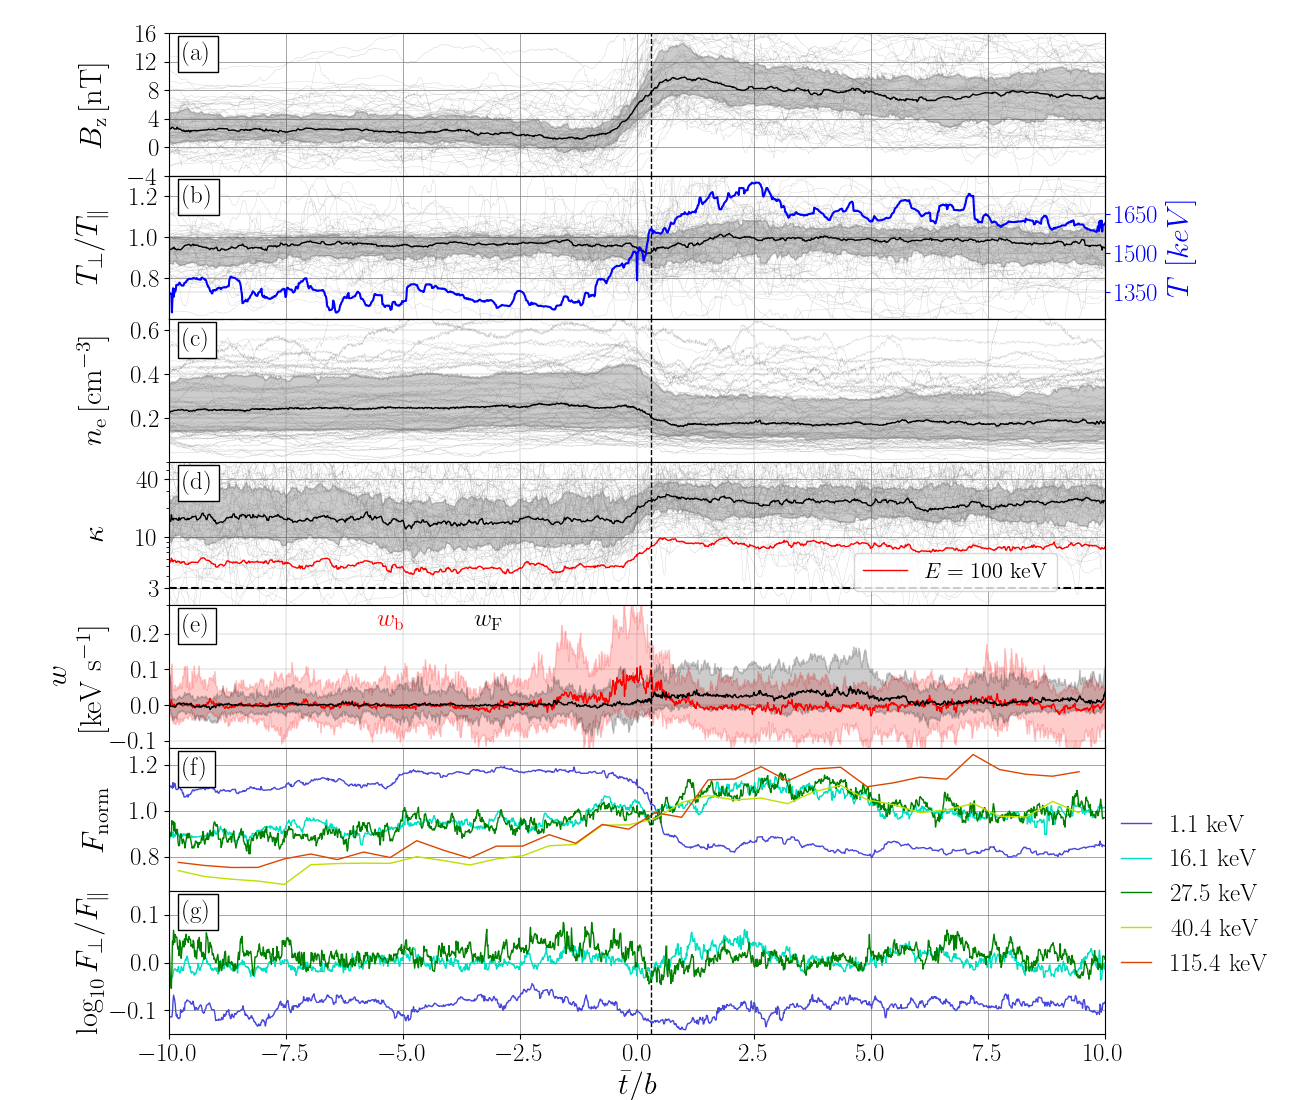

In [29]:
fig, axs = plt.subplots(7, figsize=(13, 11), sharex = True)
fig.subplots_adjust(hspace=0.0, left = 0.13, right = 0.85, bottom = 0.06, top = 0.97)
ylabel_fs = 22
lp = 1
for it in dict_ts.keys():

    b_avg_ti = dict_ts[it][f"b_avg_{ss}"]
    dbz_dt_ti = dict_ts[it][f"dbz_dt_{ss}"]
    t_ratio_ti = dict_ts[it][f"t_ratio_{ss}"]
    kappa_roll_ti = dict_ts[it][f"kappa_roll_{ss}"]
    neavg_ti = dict_ts[it][f"n_e_avg_{ss}"]
    lw = 0.2
    alpha = 0.5
    color = "grey"
    plot_line(axs[0], b_avg_ti.sel(represent_vec_tot = "z"), label="B", color = color, alpha =alpha, linewidth = lw)

    plot_line(axs[1], t_ratio_ti, color = color, alpha = alpha, linewidth = lw)

    plot_line(axs[3], kappa_roll_ti, color = color, alpha = alpha, linewidth = lw)

    plot_line(axs[2], neavg_ti, color = color, alpha = alpha, linewidth = lw)


axs[3].hlines(3, -w_ti, w_ti, color = 'black', linestyle = "--")

axs[0].set_ylabel("$B_{\mathrm{z}} \,[\mathrm{nT}]$", fontsize = ylabel_fs, labelpad = lp)
axs[1].set_ylabel("$T_{\mathrm{\perp}}/T_{\mathrm{\parallel}}$", fontsize = ylabel_fs, labelpad = lp)
axs[3].set_ylabel("$\kappa$", fontsize = ylabel_fs, labelpad = lp)

lw = 1.

b_ea_mean = ep_analysis(bs_ti)[0]
t_ratio_ea_mean = ep_analysis(t_ratios_ti)[0]
kappa_roll_ea_mean = ep_analysis(kappa_rolls_ti)[0]
kappa_extra_energy_ea_mean = ep_analysis(kappa_extra_energy_ti)[0]

b_median_line = axs[0].plot(b_ea[0].time, b_ea[0].data, color = "black", linewidth = lw, )[0]
# b_mean_line = axs[0].plot(b_ea_mean.time, b_ea_mean.data, color = "black", linewidth = lw)[0]

axs[0].fill_between(b_ea[1].time,b_ea[1], b_ea[2], color = "black", alpha = 0.2, )
# axs[0].legend(handles = [b_median_line, b_mean_line], labels = ["median", "mean"], fontsize = 12, frameon = False, 
            #   bbox_to_anchor=(0.23, 0.52), labelcolor = "linecolor", handlelength = 0,)


plot_line(axs[1], t_ratio_ea[0],linewidth = lw, color = "black", zorder = 1e4)
# plot_line(axs[1], t_ratio_ea_mean, linewidth = lw, color = "black")
axs[1].fill_between(t_ratio_ea[1].time, t_ratio_ea[1], t_ratio_ea[2], color = "black", alpha = 0.2, )

plot_line(axs[3], kappa_roll_ea[0], linewidth = lw, color = "black", zorder = 1e4)
# plot_line(axs[2], kappa_roll_ea_mean, linewidth = lw, color = "black")
axs[3].fill_between(kappa_roll_ea[1].time, kappa_roll_ea[1], kappa_roll_ea[2], color = "black", alpha = 0.2, )
plot_line(axs[3], kappa_extra_energy_ea[0], linewidth = lw, color = "red", linestyle = "-", 
          label = "$E = 100~\mathrm{keV}$")

axs[3].legend(fontsize = 16, bbox_to_anchor = (0.72, 0.44))
axs[3].set_yscale("log")
axs[-1].set_xlabel(f"${ss}$", fontsize = ylabel_fs)
axs[0].set_ylim([-4, 16])
axs[0].set_yticks([ -4, 0, 4, 8, 12, 16])
axs[1].set_ylim([0.6, 1.3])

axs[1].set_yticks([0.8, 1, 1.2])
axs[3].set_ylim([2, 6e1])
axs[3].set_yticks([3e0, 1e1, 4e1], minor = False)
axs[3].get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())

[ax.grid(lw = 0.5, color = "grey", zorder = 100) for ax in axs]
[ax.set_axisbelow(True) for ax in axs]
[ax.set_xlim(-w_ti, w_ti) for ax in axs]

axs[2].set_ylabel("$n_{\mathrm{e}} \,[\mathrm{cm^{-3}}]$", fontsize = ylabel_fs, labelpad = lp)
axs[4].set_ylabel("$w$" + "\n" + "$[\mathrm{keV}~\mathrm{s}^{-1}]$", fontsize = ylabel_fs, labelpad = lp)
axs[5].set_ylabel("$F_{\mathrm{norm}}$", fontsize = ylabel_fs, labelpad = lp)

colors = ["black", "blue", "red",]
linestyles = ["-", "--", "--"]
lw = 1
plot_line(axs[2], ne_avg_ea[0], linewidth = lw, color = "black", zorder = 1e4)
# plot_line(axs[2], ni_avg_ea_mean, linewidth = lw, color = "black")
axs[2].fill_between(ne_avg_ea[1].time, ne_avg_ea[1], ne_avg_ea[2], color = "black", alpha = 0.2, )
axs[2].set_ylim([0.001, 0.65])


plot_line(axs[4], w_betatron_ea[0], color = colors[2], linestyle = linestyles[0], linewidth = lw, label = "$w_{\mathrm{b}}$")
bet_plus_std = w_betatron_ea[0] + w_betatron_ea[-1]
bet_minus_std = w_betatron_ea[0] - w_betatron_ea[-1]
# axs[4].fill_between(bet_plus_std.time, bet_plus_std.data, bet_minus_std.data, color = colors[0], alpha = 0.2, zorder = 0)
axs[4].fill_between(w_betatron_ea[1].time,w_betatron_ea[1], w_betatron_ea[2], color = "red", alpha = 0.2,)

# plot_line(axs[1], w_betatron_ea[-1] , linewidth = lw, linestyle = linestyles[1], color = colors[1])
plot_line(axs[4], w_fermi_ea[0], color = colors[0], linestyle = linestyles[0], linewidth = lw, label = "$w_{\mathrm{F}}$")
fermi_plus_std = w_fermi_ea[0] + w_fermi_ea[-1]
fermi_minus_std = w_fermi_ea[0] - w_fermi_ea[-1]
# axs[4].fill_between(fermi_plus_std.time, fermi_plus_std.data, fermi_minus_std.data, color = colors[1], alpha = 0.2, zorder = 0)
axs[4].fill_between(w_fermi_ea[1].time,w_fermi_ea[1], w_fermi_ea[2], color = "black", alpha = 0.2, )

import matplotlib
colormap = matplotlib.colormaps.get_cmap("hot_desaturated")
colors = colormap(np.linspace(0, 0.75, len(dict_ts[0]["energies_fpi"]) + len(dict_ts[0]["energy_ranges_feeps"])))

fpi_energies_centroids = np.array([dict_ts[0][f"f_en_omni_{energy}_norm"].energy.data * 1e-3 for energy in dict_ts[0]["energies_fpi"]])

ea_lines = [axs[5].plot(f_en_omni_norm_ea[ien][0].time, 
                            f_en_omni_norm_ea[ien][0].data, 
                            color = colors[ien], linestyle = linestyles[0], 
                            linewidth = lw, label = f"${"{:0.1f}".format(fpi_energies_centroids[ien])}~\mathrm{{keV}}$")[0]
                            for ien in range(len(dict_ts[0]["energies_fpi"])) if ien not in [1, 2]]

[ea_lines.append(axs[5].plot(feeps_en_omni_norm_ea[ien][0].time,
                            feeps_en_omni_norm_ea[ien][0].data,
                            color = colors[ien + len(dict_ts[0]["energies_fpi"])], linestyle = linestyles[0],
                            linewidth = lw, label = f"${"{:0.1f}".format(dict_ts[0]["feeps_energy_centroids"][ien])}~\mathrm{{keV}}$")[0])
                            for ien in range(len(dict_ts[0]["energy_ranges_feeps"])) if ien not in [1]]

axs[5].legend(handles = ea_lines, loc = "lower right",  ncol=1,
               frameon = False, bbox_to_anchor=(1.2, -0.75), labelcolor = "linecolor", fontsize = 18,
               handlelength = 1.2, )

axs[5].grid(lw = 0.5, color = "grey")
axs[5].set_yticks([0.8, 1, 1.2,])
# time_min_n_derivative = ne_avg_ea[0].time[ne_avg_ea[0].differentiate(coord = "time").argmin()]
# time_min_1kev_flux_derivative = f_en_omni_norm_ea[0][0].time[f_en_omni_norm_ea[0][0].differentiate(coord = "time").argmin()]
ne_avg_ea_roll = ne_avg_ea[0].rolling(time = 4).mean(skipna = True)
time_min_n_derivative = ne_avg_ea_roll.time[ne_avg_ea_roll.differentiate(coord = "time").argmin()]
[ax.axvline(time_min_n_derivative, color = "black", linestyle = "--", lw =1) for ax in axs]

axs[4].set_ylim([-0.12, 0.28])

ea_lines = [axs[6].plot(f_en_perp_para_ea[ien][0].time, 
                            np.log10(f_en_perp_para_ea[ien][0]), 
                            color = colors[ien], linestyle = linestyles[0], 
                            linewidth = lw, label =f"${np.around(fpi_energies_centroids[ien], 1)}~\mathrm{{keV}}$")[0]
                            for ien in range(len(dict_ts[0]["energies_fpi"])) if ien not in [1, 2]]


axs[6].set_ylabel("$\\log_{10}{F_{\\mathrm{\\perp}} / F_{\\mathrm{\\parallel}}}$", fontsize = ylabel_fs, labelpad = lp)


axs[6].grid(lw = 0.5, color = "grey")
[ax.grid() for ax in axs[:2]]
[ax.grid(lw = 0.5, color = "grey") for ax in axs[:2]]
axs[6].set_ylim([-0.15, 0.15])

axs[4].legend(frameon = False, bbox_to_anchor=(0.38, 1.13), fontsize = 18, 
              labelcolor = "linecolor", handlelength = 0, loc = "upper right", ncols =2)
axs[-1].set_xlabel(f"$\\bar{{t}}/{ss}$", fontsize = ylabel_fs)
[ax.set_xlim(-w_ti, w_ti) for ax in axs]

axs1_secy = axs[1].twinx()
plot_line(axs1_secy, temp_ea[0], color = "blue", linewidth = 1.5, label = "$T$")
axs1_secy.set_ylabel("$T$ [$keV$]" , fontsize = ylabel_fs, color = "blue")
axs1_secy.tick_params(axis="y", colors = "blue")

make_labels(axs = axs, pos = ([0.015, 0.81]), bbox=dict(facecolor='white', edgecolor='black', ),)

fig.align_ylabels(axs)

# fig.savefig("figure_2.png", bbox_inches = "tight", dpi = 500)

In [10]:
from scipy import constants
ev2j = constants.physical_constants["electron volt-joule relationship"][0]

matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"
matplotlib.rcParams["font.size"] = "14"

[13-Mar-26 07:25:07] WARNING: <>:9: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:30: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:32: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:38: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:9: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:30: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:32: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: <>:38: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 07:25:07] WARNING: /tmp/ipykernel_414233/2641444761.py:9: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel("$B_{\mathrm{z}} \,[\mathrm{nT}]$", fontsize = ylabel_fs, labelpad = lp)

[13-Mar-26 07:25:07] WARNING: /tmp/ipykernel_414233/2641444761.py:30: SyntaxWarning: invalid escape sequence '\m'
  axs[1].set_ylabel("$W$"

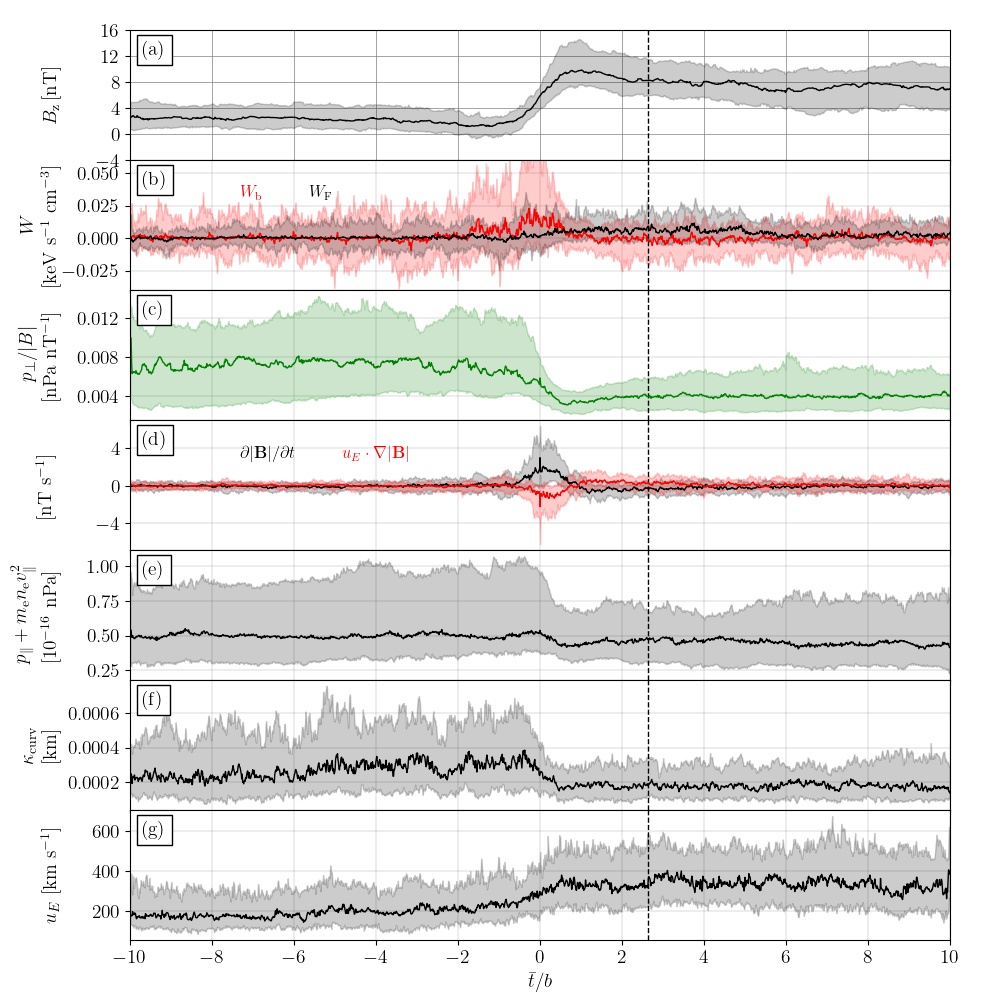

In [11]:
from matplotlib.pyplot import plot


fig, axs = plt.subplots(7, figsize=(10, 10), sharex = True)
fig.subplots_adjust(hspace=0.0, left = 0.13, right = 0.95, bottom = 0.06, top = 0.97)
ylabel_fs = 14
lp = 1

axs[0].set_ylabel("$B_{\mathrm{z}} \,[\mathrm{nT}]$", fontsize = ylabel_fs, labelpad = lp)

lw = 1.

b_ea_mean = ep_analysis(bs_ti)[0]
t_ratio_ea_mean = ep_analysis(t_ratios_ti)[0]
kappa_roll_ea_mean = ep_analysis(kappa_rolls_ti)[0]
kappa_extra_energy_ea_mean = ep_analysis(kappa_extra_energy_ti)[0]

b_median_line = axs[0].plot(b_ea[0].time, b_ea[0].data, color = "black", linewidth = lw, )[0]

axs[0].fill_between(b_ea[1].time,b_ea[1], b_ea[2], color = "black", alpha = 0.2, )

axs[-1].set_xlabel(f"${ss}$", fontsize = ylabel_fs)
axs[0].set_ylim([-4, 16])
axs[0].set_yticks([ -4, 0, 4, 8, 12, 16])

[ax.grid(lw = 0.5, color = "grey", zorder = 100) for ax in axs]
[ax.set_axisbelow(True) for ax in axs]
[ax.set_xlim(-w_ti, w_ti) for ax in axs]

axs[1].set_ylabel("$W$" + "\n" + "$[\mathrm{keV}~\mathrm{s}^{-1}~\mathrm{cm}^{-3}]$", fontsize = ylabel_fs, labelpad = lp)

plot_line(axs[1], W_betatron_ea[0], color = 'red', linestyle = linestyles[0], linewidth = lw, label = "$W_{\mathrm{b}}$")


axs[1].fill_between(W_betatron_ea[1].time,W_betatron_ea[1], W_betatron_ea[2], color = "red", alpha = 0.2,)


plot_line(axs[1], W_fermi_ea[0], color = 'black', linestyle = linestyles[0], linewidth = lw, label = "$W_{\mathrm{F}}$")


axs[1].fill_between(W_fermi_ea[1].time,W_fermi_ea[1], W_fermi_ea[2], color = "black", alpha = 0.2, )

axs[1].legend(loc = "upper left", fontsize = 12, bbox_to_anchor = (0.1, 0.92), frameon = False, handlelength = 0, 
              labelcolor = "linecolor", labelspacing = 0.2, ncol = 2)

axs[5].grid(lw = 0.5, color = "grey")
axs[5].set_yticks([0.9, 1, 1.1,])
time_min_n_derivative = ne_avg_ea[0].time[ne_avg_ea[0].differentiate(coord = "time").argmin()]
time_min_1kev_flux_derivative = f_en_omni_norm_ea[0][0].time[f_en_omni_norm_ea[0][0].differentiate(coord = "time").argmin()]
[ax.axvline(time_min_n_derivative, color = "black", linestyle = "--", lw =1) for ax in axs]

axs[1].set_ylim([-0.04, 0.06])

axs[-1].set_xlabel(f"$\\bar{{t}}/{ss}$", fontsize = ylabel_fs)
[ax.set_xlim(-w_ti, w_ti) for ax in axs]
axs[-1].set_xticks([-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10])


plot_line(axs[2], pe_perp_B_mag_ea[0], color = "green", linewidth = lw, label = "$P_{e \\perp} / B$")
pe_perp_B_mag_plus_std = pe_perp_B_mag_ea[0] + pe_perp_B_mag_ea[-1]
pe_perp_B_mag_minus_std = pe_perp_B_mag_ea[0] - pe_perp_B_mag_ea[-1]
axs[2].fill_between(pe_perp_B_mag_ea[1].time,pe_perp_B_mag_ea[1], pe_perp_B_mag_ea[2], color = "green", alpha = 0.2, )
axs[2].set_ylabel("$p_{\\perp} / |B|$ \n [$\\rm nPa~nT^{-1}$]", fontsize = ylabel_fs, labelpad = lp)

plot_line(axs[3], db_dt_5ps_ea[0], color = "black", linewidth = lw, label = "$\\partial \\mathbf{|B|} / \\partial t$")
db_dt_5ps_plus_std = db_dt_5ps_ea[0] + db_dt_5ps_ea[-1]
db_dt_5ps_minus_std = db_dt_5ps_ea[0] - db_dt_5ps_ea[-1]
axs[3].fill_between(db_dt_5ps_ea[1].time,db_dt_5ps_ea[1], db_dt_5ps_ea[2], color = "black", alpha = 0.2, )

plot_line(axs[3], uE_dot_gradB_avg_ea[0], color = "red", linewidth = lw, label = "$u_{E} \\cdot \\nabla \\mathbf{|B|}$")
uE_dot_gradB_plus_std = uE_dot_gradB_avg_ea[0] + uE_dot_gradB_avg_ea[-1]
uE_dot_gradB_minus_std = uE_dot_gradB_avg_ea[0] - uE_dot_gradB_avg_ea[-1]
axs[3].fill_between(uE_dot_gradB_avg_ea[1].time,uE_dot_gradB_avg_ea[1], uE_dot_gradB_avg_ea[2], color = "red", alpha = 0.2, )
axs[3].set_ylabel("[$\\rm nT~s^{-1}$]")

axs[3].legend(fontsize = 12, bbox_to_anchor = (0.1, 0.92), loc = "upper left", frameon = False, handlelength = 0, 
              labelcolor = "linecolor", labelspacing = 0.2, ncol = 2)

plot_line(axs[4], pe_para_mnv2_ea[0]*1e16, color = "black", linewidth = lw, label = "$P_{e \\parallel} ~ m n v_{\\mathrm{th}, e \\parallel}^{2}$")
pe_para_mnv2_plus_std = pe_para_mnv2_ea[0] + pe_para_mnv2_ea[-1]* ev2j**(-1)
pe_para_mnv2_minus_std = pe_para_mnv2_ea[0] - pe_para_mnv2_ea[-1]* ev2j**(-1)
axs[4].fill_between(pe_para_mnv2_ea[1].time,pe_para_mnv2_ea[1]*1e16, pe_para_mnv2_ea[2]*1e16, color = "black", alpha = 0.2, )
axs[4].set_ylabel("$p_{\\parallel} + m_{\\rm e} n_{\\rm e} v_{\\parallel}^{2}$ \n [$\\rm 10^{-16}~nPa$]", fontsize = ylabel_fs, labelpad = lp)

plot_line(axs[5], curv_ea[0], color = "black", linewidth = lw, label = "$\\kappa_{\\rm curv}$")
axs[5].fill_between(curv_ea[1].time, curv_ea[1], curv_ea[2], alpha = 0.2, color = "black")
axs[5].set_ylabel("$\\kappa_{\\rm curv}$ \n [$\\rm km$]", fontsize = ylabel_fs, labelpad = lp)

plot_line(axs[6], u_E_ea[0], color = "black", linewidth = lw, label = "$u_{E}$")
axs[6].fill_between(u_E_ea[1].time, u_E_ea[1], u_E_ea[2], alpha = 0.2, color = "black")
axs[6].set_ylabel("$u_{E}$ [$\\mathrm{km~s^{-1}}$]", fontsize = ylabel_fs, labelpad = lp)

make_labels(axs = axs, pos = ([0.015, 0.81]), bbox=dict(facecolor='white', edgecolor='black', ),)

fig.align_ylabels(axs)

# fig.savefig("paper_figs/guiding_center_terms.png", bbox_inches = "tight", dpi = 500)